# Extra: Web feature and web map services (WFS and WMS)

> **Optional reading**
> This page is an *extra*: it is not part of the weekly lessons or exercises,
> and you do not need it to complete the course. It is here for those who want
> to know what is going on behind the web addresses we use to load data, and
> for anyone who needs to work with such services in their own projects.

In this course, we mostly read spatial data from files that we have downloaded
to our computer. But a lot of data is *not* stored in a file somewhere, but is
served live by an organisation that maintains it: Statistics Finland, the City
of Helsinki, the Helsinki Region Environmental Services (HSY), and many more.
They publish their data through **web services** that follow open standards of
the [Open Geospatial Consortium (OGC)](https://www.ogc.org/). In the lessons,
we already used one of them without much explanation: for instance, we
loaded the population grid from HSY’s *WFS* in
[lesson 3](../../lessons/lesson-3/spatial-join).

Here, we take a closer look at how these services work, and how you can use
them from Python. We use real services from Finland as examples.

**Sources:** Parts of this page are based on the documentation of
[OWSLib](https://owslib.readthedocs.io/) and of
[GeoServer](https://docs.geoserver.org/), the software that runs most of the
Finnish services we use.


## What you will learn

- the difference between a *WFS* and a *WMS*,
- how to connect to a web service and find out which layers it offers,
- how to download vector features from a WFS into a `GeoDataFrame`, and narrow
  the request down (CRS, extent, attribute filter, number of features),
- how to request a map image from a WMS and combine it with vector data in a
  map,
- how to recognise and fix the most common problems when working with web
  services.

---


## Two kinds of services: WFS and WMS

The two most important OGC services for our work are the **Web Feature
Service (WFS)** and the **Web Map Service (WMS)**:

| | **WFS** (Web Feature Service) | **WMS** (Web Map Service) |
|---|---|---|
| You get | the *features*: geometries and attributes | a *picture* of a map (PNG, JPEG, …) |
| Comparable to | downloading a shapefile or GeoPackage | taking a screenshot of a web map |
| Typical use | analysis, queries, joins, own maps | background maps, quick looks, very large data sets |
| Styling | you decide (in Python) | the server decides (predefined *styles*) |
| In Python | `geopandas.read_file()` | `owslib` and `matplotlib` |

There are more members in the family. A **WMTS** serves pre-rendered map
*tiles* (that is what most web map backgrounds use), and a **WCS** serves raster
*data* (not just a picture of it). Here, we focus on WFS and WMS.

All of these services are used in the same way: we send a request to a *URL*,
and the server sends back a response. Which request we send is defined by
standardised *parameters*. This also means that you can use the knowledge from
this page with any WFS or WMS in the world, not only the Finnish ones.

<div style="border: 1px solid #cce5ff; background-color: #e9f7fd; padding: 15px; border-radius: 5px;">

**Web services in Finland**

Here are a few providers of open geospatial web services in Finland. We use the
first three below:

- **Statistics Finland**: statistical areas (municipalities, regions, …),
  population grids: `https://geo.stat.fi/geoserver/wfs` and `…/wms`
- **HSY** (Helsinki Region Environmental Services): population grid,
  land cover, air quality, aerial photographs, …:
  `https://kartta.hsy.fi/geoserver/wfs` and `…/wms`
- **City of Helsinki**: city districts, parks, parking, base maps,
  aerial photographs, …: `https://kartta.hel.fi/ws/geoserver/avoindata/wfs`
  and `…/wms`
- **Finnish Meteorological Institute (FMI)**: weather observations and
  forecasts: [en.ilmatieteenlaitos.fi/open-data](https://en.ilmatieteenlaitos.fi/open-data)
- **National Land Survey of Finland (NLS/MML)**: topographic data, base maps,
  elevation models: [maanmittauslaitos.fi](https://www.maanmittauslaitos.fi/en);
  you need to register for a free *API key* to use these services.

</div>

---


## Anatomy of a request

A request to a web service is nothing but a *URL* with a few *parameters* (the
*query string*, everything after the `?`). The simplest request asks a service
to describe itself. It is called **GetCapabilities**, and it needs three
parameters:

- `service`: which type of service we are talking to (`WFS` or `WMS`),
- `version`: which version of the standard we want to use, and
- `request`: what we want to do.

Let’s build such a URL for Statistics Finland’s WFS. We use the `requests`
package for it, because it takes care of writing the parameters correctly into
the URL (special characters such as `:` and spaces need to be *encoded*):

In [1]:
#!pip install owslib

In [2]:
import io
import json
import pathlib
import xml.etree.ElementTree

import geopandas
import matplotlib.pyplot as plt
import pandas
import requests
from owslib.wfs import WebFeatureService
from owslib.wms import WebMapService

NOTEBOOK_PATH = pathlib.Path().resolve()
DATA_DIRECTORY = NOTEBOOK_PATH / "data"
DATA_DIRECTORY.mkdir(exist_ok=True)

In [3]:
STATISTICS_FINLAND_WFS = "https://geo.stat.fi/geoserver/wfs"

request = requests.Request(
    "GET",
    STATISTICS_FINLAND_WFS,
    params={
        "service": "WFS",
        "version": "2.0.0",
        "request": "GetCapabilities",
    },
)
print(request.prepare().url)

https://geo.stat.fi/geoserver/wfs?service=WFS&version=2.0.0&request=GetCapabilities


Copy the printed address into your web browser: you will see a (long) XML
document that describes everything the service can do and all the layers it
offers. That is what *OWSLib* reads for us in the next step. You will probably
not want to read it yourself.

These are the requests that we will use:

| Service | Request | What it does |
|---|---|---|
| WFS | `GetCapabilities` | describes the service and lists its layers |
| WFS | `DescribeFeatureType` | lists the attribute columns of a layer |
| WFS | `GetFeature` | downloads features of a layer |
| WMS | `GetCapabilities` | describes the service and lists its layers |
| WMS | `GetMap` | returns a map image |
| WMS | `GetFeatureInfo` | returns the attributes of the feature at a pixel |
| WMS | `GetLegendGraphic` | returns the legend of a layer |

---


## Working with a WFS

### Connect to the service

[OWSLib](https://owslib.readthedocs.io/) is a Python package that sends the
requests for us and translates the responses into Python objects. To connect
to a WFS, create a `WebFeatureService` object. Behind the scenes, it sends the
`GetCapabilities` request that we have just seen.

In [4]:
wfs = WebFeatureService(STATISTICS_FINLAND_WFS, version="2.0.0")

<div style="border-left: 5px solid #f5c242; padding: 10px; background-color: #fff3cd; margin: 10px 0;">

**Note: Service version**

The `version` parameter tells the server which version of the WFS standard we
speak. The most recent one is `2.0.0`; many services also offer `1.1.0` or
`1.0.0`. We use `2.0.0` throughout this page. If you find older code examples
on the internet, you will notice that some parameters have different names in
older versions (for example `maxFeatures` instead of `count`, and `typeName`
instead of `typeNames`).

</div>

The service describes itself. Let’s look at its title, who runs it, and which
operations it offers:

In [5]:
print(wfs.identification.title)
print(wfs.provider.name)
print([operation.name for operation in wfs.operations][:3])

Tilastokeskuksen palvelurajapinta (WFS)
Tilastokeskus
['GetCapabilities', 'DescribeFeatureType', 'GetFeature']


Those are the three operations we will use. (The other operations are more
advanced, for example for editing data in the service.)

### Explore the layers

A web service typically offers many *layers* (in a WFS they are called *feature
types*). They are stored in the `contents` of the service object, which works
like a dictionary: the keys are the *layer names*. Let’s see how many layers
this service offers, and look at the first few of them:

In [6]:
layer_names = list(wfs.contents)

print(f"The service offers {len(layer_names)} layers.")
layer_names[:5]

The service offers 423 layers.


['tilastointialueet:avi1000k',
 'tilastointialueet:avi4500k',
 'tilastointialueet:avi1000k_2013',
 'tilastointialueet:avi4500k_2013',
 'tilastointialueet:avi1000k_2014']

Layer names consist of a *workspace* (here `tilastointialueet`, i.e.,
‘statistical areas’), a colon, and the actual name of the layer. Hundreds of
layers are difficult to browse in a list, but we can search them, for
instance for all municipality (*kunta*) layers of the year 2026:

In [7]:
for name in layer_names:
    if "kunta" in name and "2026" in name:
        print(f"{name:45}{wfs.contents[name].title}")

tilastointialueet:kunta1000k_2026            Kunnat 2026 (1:1 000 000)
tilastointialueet:kunta4500k_2026            Kunnat 2026 (1:4 500 000)
tilastointialueet:maakunta1000k_2026         Maakunnat 2026 (1:1 000 000)
tilastointialueet:maakunta4500k_2026         Maakunnat 2026 (1:4 500 000)
tilastointialueet:seutukunta1000k_2026       Seutukunnat 2026 (1:1 000 000)
tilastointialueet:seutukunta4500k_2026       Seutukunnat 2026 (1:4 500 000)


<div style="border: 1px solid #d4edda; background-color: #e6f4ea; padding: 15px; border-radius: 5px;">

**Tip: Layers for every year**

Statistics Finland publishes the statistical areas for each year separately,
in two levels of generalisation: `1000k` for maps at the scale of 1:1 000 000,
and `4500k` for 1:4 500 000. For analysis, you should always use the most
detailed version that is available, and make sure to pick the year that fits
your data.

</div>

Each layer has *metadata* that help us decide whether it is the layer we are
looking for. Let’s have a look at the layer of the municipalities in 2026, in
the 1:4 500 000 generalisation:

In [8]:
layer = wfs.contents["tilastointialueet:kunta4500k_2026"]

print(f"Title:    {layer.title}")
print(f"Abstract: {layer.abstract}")
print(f"CRS:      {[str(crs) for crs in layer.crsOptions]}")
print(f"Extent:   {layer.boundingBoxWGS84}")

Title:    Kunnat 2026 (1:4 500 000)
Abstract: Kunnat 2026 (1:4 500 000)
CRS:      ['urn:ogc:def:crs:EPSG::3067']
Extent:   (16.16859974410194, 59.662186543973164, 33.10757972682034, 70.09414558842893)


The *abstract* often explains what the data are and where they come from. The
*CRS options* list the coordinate reference systems the layer can be served
in; the first one is usually the layer’s native CRS. Here, it is `EPSG:3067` (ETRS-TM35FIN),
the national projected CRS of Finland. The *extent* is the bounding box of the
layer in WGS 84 longitudes and latitudes (`minx, miny, maxx, maxy`).

Before downloading anything, we can also ask the service which *attribute
columns* the layer has, using a `DescribeFeatureType` request. OWSLib wraps it
into the method `get_schema()`:

In [9]:
schema = wfs.get_schema("tilastointialueet:kunta4500k_2026")

print(f"Geometry type: {schema['geometry']}")
for column, data_type in schema["properties"].items():
    print(f"{column:10}{data_type}")

Geometry type: GeometryCollection
id        int
kunta     string
vuosi     int
nimi      string
namn      string
name      string


Municipalities have a code (`kunta`), a year (`vuosi`), and a name in Finnish
(`nimi`), Swedish (`namn`), and English (`name`). (The geometry type
`GeometryCollection` only means that the service does not tell us more
precisely which type of geometry to expect; these are polygons.) Finally, let’s see in which
file formats the service can deliver the data (the `outputFormat`):

In [10]:
get_feature = wfs.getOperationByName("GetFeature")
get_feature.parameters["outputFormat"]["values"]

['application/gml+xml; version=3.2',
 'GML2',
 'KML',
 'SHAPE-ZIP',
 'application/json',
 'application/vnd.google-earth.kml xml',
 'application/vnd.google-earth.kml+xml',
 'csv',
 'excel',
 'excel2007',
 'gml3',
 'gml32',
 'json',
 'text/csv',
 'text/xml; subtype=gml/2.1.2',
 'text/xml; subtype=gml/3.1.1',
 'text/xml; subtype=gml/3.2']

Among them are *GML* (the default of all WFS), *Shapefile* (`SHAPE-ZIP`), *CSV*,
and `application/json`, i.e., *GeoJSON*. We will use the latter: it is
compact, and geopandas reads it without problems.

---


### Download features

Now we are ready to download the municipalities. For that, we send a
**GetFeature** request. Its most important parameters are:

- `typeNames`: the name of the layer we want,
- `outputFormat`: the file format in which we want to receive the features, and
- `srsName`: the CRS in which we want to receive the coordinates.

As the response of a `GetFeature` request is a *file* in a spatial data format,
we can use the same function as always to read it, `geopandas.read_file()`.
It does not only accept file names, but also URLs. We only need to build the
URL with all the parameters, just like before:

In [11]:
request = requests.Request(
    "GET",
    STATISTICS_FINLAND_WFS,
    params={
        "service": "WFS",
        "version": "2.0.0",
        "request": "GetFeature",
        "typeNames": "tilastointialueet:kunta4500k_2026",
        "outputFormat": "application/json",
        "srsName": "EPSG:3067",
    },
)
request_url = request.prepare().url
print(request_url)

municipalities = geopandas.read_file(request_url)
municipalities.head()

https://geo.stat.fi/geoserver/wfs?service=WFS&version=2.0.0&request=GetFeature&typeNames=tilastointialueet%3Akunta4500k_2026&outputFormat=application%2Fjson&srsName=EPSG%3A3067


,id,kunta,vuosi,nimi,namn,name,geometry
0,1,005,2026,Alajärvi,Alajärvi,Alajärvi,"POLYGON ((366787.924 7001300.583, 362458.797 6..."
1,2,009,2026,Alavieska,Alavieska,Alavieska,"POLYGON ((382543.364 7120022.976, 372645.944 7..."
2,3,010,2026,Alavus,Alavo,Alavus,"POLYGON ((343298.204 6961570.195, 345569.224 6..."
3,4,016,2026,Asikkala,Asikkala,Asikkala,"POLYGON ((436139.680 6798279.085, 435912.756 6..."
4,5,018,2026,Askola,Askola,Askola,"POLYGON ((426631.036 6720528.076, 432565.266 6..."


That worked. We have a regular `GeoDataFrame`, with one row per municipality.
Let’s check the CRS and the number of rows, and draw a map:

EPSG:3067
308 municipalities


Text(0.5, 1.0, 'Municipalities of Finland, 2026')

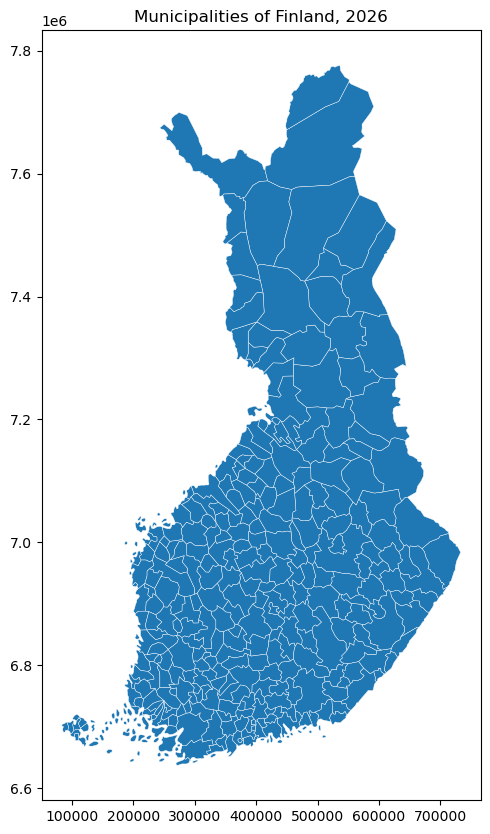

In [12]:
print(municipalities.crs)
print(f"{len(municipalities)} municipalities")

ax = municipalities.plot(figsize=(6, 10), edgecolor="white", linewidth=0.3)
ax.set_title("Municipalities of Finland, 2026")

---


### Make writing requests easier

You will send many requests, and writing out the same dictionary of
parameters each time is tedious and error-prone. Let’s write a small *function*
that does it for us. All the parameters that never change are set inside the
function; the others are passed as arguments.

<div style="border: 1px solid #d4edda; background-color: #e6f4ea; padding: 15px; border-radius: 5px;">

**Tip: Arbitrary keyword arguments**

The two asterisks in `**parameters` collect all additional *keyword arguments*
that are passed to the function into a *dictionary*. We can then add them to
the parameters of the request. This way, our function can handle any
parameter that a WFS knows, without us having to list all of them.

</div>

In [13]:
def build_wfs_url(service_url, layer_name, **parameters):
    """Build the URL of a WFS GetFeature request that returns GeoJSON."""
    request_parameters = {
        "service": "WFS",
        "version": "2.0.0",
        "request": "GetFeature",
        "typeNames": layer_name,
        "outputFormat": "application/json",
    }
    request_parameters.update(parameters)

    request = requests.Request("GET", service_url, params=request_parameters)
    return request.prepare().url

Let’s try whether it gives us the same result as before:

In [14]:
municipalities = geopandas.read_file(
    build_wfs_url(
        STATISTICS_FINLAND_WFS,
        "tilastointialueet:kunta4500k_2026",
        srsName="EPSG:3067",
    )
)
len(municipalities)

308

---


## Request parameters of a WFS

Downloading the entire layer is not always what we want. Layers can be large,
and often we need only a part of it. The good news: a WFS can do the selection
*on the server*, so that we only download what we need. This is faster, and it
is also kinder to the server. Here are the most useful parameters.

### Number of features: `count`

To limit the number of features that are returned, pass `count`. This is
handy to have a first look at a very large layer:

In [15]:
sample = geopandas.read_file(
    build_wfs_url(
        STATISTICS_FINLAND_WFS,
        "tilastointialueet:kunta4500k_2026",
        count=5,
    )
)
sample[["kunta", "nimi", "name"]]

,kunta,nimi,name
0,005,Alajärvi,Alajärvi
1,009,Alavieska,Alavieska
2,010,Alavus,Alavus
3,016,Asikkala,Asikkala
4,018,Askola,Askola


### Attribute columns: `propertyName`

If we only need some of the columns, we can list them in `propertyName`,
separated by commas. The geometry column of this layer is called `geom` (see
the schema above), and it is not included unless we ask for it:

In [16]:
names_only = geopandas.read_file(
    build_wfs_url(
        STATISTICS_FINLAND_WFS,
        "tilastointialueet:kunta4500k_2026",
        propertyName="nimi,geom",
    )
)
names_only.columns

Index(['id', 'nimi', 'geometry'], dtype='object')

### Attribute filter: `cql_filter`

The most powerful way to select features is a *filter* that is evaluated by the
server. *GeoServer* (the software behind most Finnish services) understands
the **CQL** language (*Common Query Language*) through the parameter
`cql_filter`. Its syntax is close to SQL’s `WHERE` clause. Strings are written in
single quotes:

In [17]:
helsinki = geopandas.read_file(
    build_wfs_url(
        STATISTICS_FINLAND_WFS,
        "tilastointialueet:kunta4500k_2026",
        cql_filter="nimi = 'Helsinki'",
    )
)
helsinki[["kunta", "nimi", "name"]]

,kunta,nimi,name
0,091,Helsinki,Helsinki


These are the most important elements of CQL:

| Example | Meaning |
|---|---|
| `nimi = 'Helsinki'` | equal to (also `<>`, `<`, `<=`, `>`, `>=`) |
| `nimi LIKE 'Ki%'` | text pattern (`%` stands for any number of characters) |
| `nimi IN ('Espoo', 'Vantaa')` | one of several values |
| `nimi = 'Espoo' OR nimi = 'Vantaa'` | combine conditions (`AND`, `OR`, `NOT`) |
| `BBOX(geom, 380000, 6670000, 400000, 6690000)` | spatial filter by extent |

Let’s find all municipalities whose name starts with *Ki*:

In [18]:
ki_municipalities = geopandas.read_file(
    build_wfs_url(
        STATISTICS_FINLAND_WFS,
        "tilastointialueet:kunta4500k_2026",
        cql_filter="nimi LIKE 'Ki%'",
    )
)
ki_municipalities["nimi"].to_list()

['Kihniö',
 'Kinnula',
 'Kirkkonummi',
 'Kitee',
 'Kittilä',
 'Kiuruvesi',
 'Kivijärvi']

<div style="border-left: 5px solid #f5c242; padding: 10px; background-color: #fff3cd; margin: 10px 0;">

**Note: CQL is a GeoServer extension**

`cql_filter` is not part of the WFS standard. The standard way of filtering
uses an XML-based language called *Filter Encoding* (parameter `filter`),
which is much more verbose. Most services in Finland run on GeoServer (or
the similar MapServer), and understand CQL. If a service does not understand
`cql_filter`, it silently ignores it and sends you *all* features. **Always
check the number of rows you received!**

</div>

### Spatial filter: `bbox`

To only get the features within (or, to be exact, *intersecting*) a bounding
box, use the parameter `bbox`. It takes four coordinates in the order
`minx, miny, maxx, maxy`, followed by the CRS in which they are given. Here is
a bounding box around the Helsinki region, in ETRS-TM35FIN (EPSG:3067):

In [19]:
region = geopandas.read_file(
    build_wfs_url(
        STATISTICS_FINLAND_WFS,
        "tilastointialueet:kunta4500k_2026",
        bbox="380000,6670000,400000,6690000,EPSG:3067",
        srsName="EPSG:3067",
    )
)
region["nimi"].to_list()

['Helsinki', 'Vantaa', 'Sipoo']

Note that the server returns all municipalities that *touch* the bounding
box, and they are complete, i.e., they are not clipped to its edges.

### Number of results: `resultType=hits`

How many features does a layer have, or how many does a filter select? We can
ask the server to only *count*, without sending the features, with
`resultType=hits`. The response is a small XML document, with the number of
features in the attribute `numberMatched`:

In [20]:
response = requests.get(
    build_wfs_url(
        STATISTICS_FINLAND_WFS,
        "tilastointialueet:kunta4500k_2026",
        resultType="hits",
    )
)
xml.etree.ElementTree.fromstring(response.content).attrib["numberMatched"]

'308'

### Download in pages: `startIndex`

Some services limit the number of features that they return in one response,
so that single requests do not take forever, or overwhelm the server. If a layer
has more features than the limit, you only get the first part. To get the
rest, you request the data *in pages*: combine `count` (the size of a page)
with `startIndex` (the number of features to skip). To make sure that the
pages do not overlap, also sort the features with `sortBy`.

Let’s look at this using HSY’s population grid, which has several thousand
cells. Of course, we could get them in one go, but let’s pretend that the
server limits us to 2 000 features per request:

In [21]:
HSY_WFS = "https://kartta.hsy.fi/geoserver/wfs"
POPULATION_GRID = "asuminen_ja_maankaytto:Vaestotietoruudukko_2025"

page_size = 2000
start_index = 0
pages = []

while True:
    page = geopandas.read_file(
        build_wfs_url(
            HSY_WFS,
            POPULATION_GRID,
            srsName="EPSG:3879",
            sortBy="index",
            count=page_size,
            startIndex=start_index,
        )
    )
    print(f"Received {len(page)} features, starting at {start_index}")
    pages.append(page)

    if len(page) < page_size:
        break  # the last page is not completely filled
    start_index += page_size

population_grid = pandas.concat(pages, ignore_index=True)
print(f"In total: {len(population_grid)} grid cells, CRS: {population_grid.crs}")

Received 2000 features, starting at 0
Received 2000 features, starting at 2000
Received 1826 features, starting at 4000
In total: 5826 grid cells, CRS: EPSG:3879


Using `pandas.concat()`, we put the pages back together into one data frame.
Check the result: HSY’s population grid has the population (`asukkaita`) of
each 250 m × 250 m grid cell.

Text(0.5, 1.0, 'Population in the Helsinki metropolitan area, 2025')

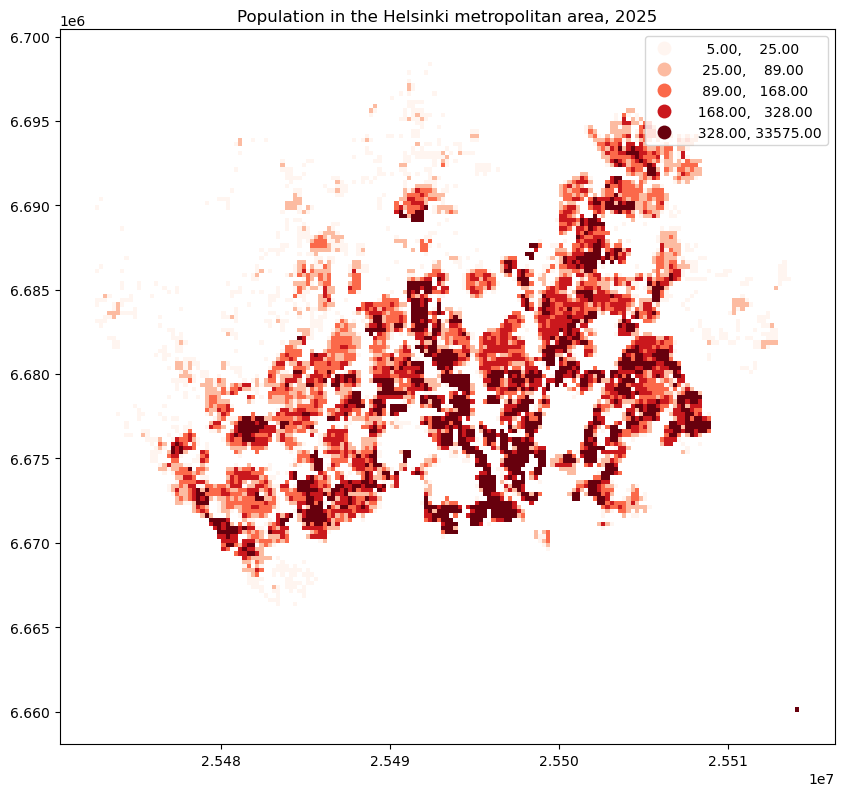

In [22]:
ax = population_grid.plot(
    figsize=(10, 10),
    column="asukkaita",
    cmap="Reds",
    scheme="quantiles",
    legend=True,
)
ax.set_title("Population in the Helsinki metropolitan area, 2025")

<div style="border: 1px solid #d4edda; background-color: #e6f4ea; padding: 15px; border-radius: 5px;">

**Tip: Be kind to the server**

Web services are shared resources. Request only what you need (use `bbox`,
`cql_filter`, `propertyName`, and `count`), and do not download the same
data again and again when you run your notebook repeatedly: save it to a file
once (see below) and read the file afterwards.

</div>

---


## Putting it together: green areas in Kallio

Let’s use what we have learned in a small case study. The City of Helsinki
publishes the register of its green areas (`YLRE_Viheralue_alue`), and its city
districts (`Kaupunginosajako`) in a WFS. We want to look at the green areas of
the district of **Kallio**.

First, connect to the service and explore the two layers. This time, we only
look at the metadata that is important for us:

In [23]:
HELSINKI_WFS = "https://kartta.hel.fi/ws/geoserver/avoindata/wfs"

helsinki_wfs = WebFeatureService(HELSINKI_WFS, version="2.0.0")

for layer_name in ["avoindata:Kaupunginosajako", "avoindata:YLRE_Viheralue_alue"]:
    layer = helsinki_wfs.contents[layer_name]
    print(layer_name)
    print(f"  CRS options: {[str(crs) for crs in layer.crsOptions]}")
    print(f"  Columns:     {list(helsinki_wfs.get_schema(layer_name)['properties'])}")
    print(f"  Geometry:    {helsinki_wfs.get_schema(layer_name)['geometry_column']}")

avoindata:Kaupunginosajako
  CRS options: ['urn:ogc:def:crs:EPSG::3879', 'urn:ogc:def:crs:EPSG::3067', 'urn:ogc:def:crs:EPSG::4326', 'urn:ogc:def:crs:EPSG::3857']
  Columns:     ['id', 'aluejako', 'kunta', 'tunnus', 'nimi_fi', 'nimi_se', 'yhtluontipvm', 'yhtmuokkauspvm', 'yhtdatanomistaja', 'paivitetty_tietopalveluun']
  Geometry:    geom
avoindata:YLRE_Viheralue_alue
  CRS options: ['urn:ogc:def:crs:EPSG::3879', 'urn:ogc:def:crs:EPSG::3067', 'urn:ogc:def:crs:EPSG::4326', 'urn:ogc:def:crs:EPSG::3857']
  Columns:     ['viheralue_id', 'puistonumero', 'puistonimi_id', 'puiston_nimi', 'osoite', 'kaavamerkinta', 'kaavamerkinta_teksti', 'luokka', 'kayttotark_id', 'kayttotarkoitus', 'omistaja', 'vuokraus', 'vuokraaja', 'rakentamisen_tila', 'kaupunginosa', 'osa_alue', 'suurpiiri', 'viheralueen_pa', 'alue_luonti_pvm', 'paivitetty_pvm', 'datanomistaja', 'paivitetty_tietopalveluun']
  Geometry:    geom


Both layers are available in `EPSG:3879` (ETRS-GK25), which is the CRS that
the City of Helsinki uses for its data. We continue to work in this CRS.

The city districts have the name in the column `nimi_fi`, written in capital
letters. We use `cql_filter` to download only Kallio:

In [24]:
kallio = geopandas.read_file(
    build_wfs_url(
        HELSINKI_WFS,
        "avoindata:Kaupunginosajako",
        srsName="EPSG:3879",
        cql_filter="nimi_fi = 'KALLIO'",
    )
)
kallio[["tunnus", "nimi_fi", "nimi_se"]]

,tunnus,nimi_fi,nimi_se
0,11,KALLIO,BERGHÄLL


Now we use the *extent* of Kallio to ask for the green areas. The attribute
`total_bounds` of a `GeoDataFrame` gives us the bounding box as an array of
`minx, miny, maxx, maxy`. We only need to convert it into the text that the
`bbox` parameter expects.

The green area register has more than 20 columns (see the list above), but we
only need a few of them for our map. So let’s also use `propertyName` to
download only these, and the geometry (`geom`):

In [25]:
minx, miny, maxx, maxy = kallio.total_bounds
kallio_bbox = f"{minx},{miny},{maxx},{maxy},EPSG:3879"
print(kallio_bbox)

green_areas = geopandas.read_file(
    build_wfs_url(
        HELSINKI_WFS,
        "avoindata:YLRE_Viheralue_alue",
        srsName="EPSG:3879",
        bbox=kallio_bbox,
        propertyName="puiston_nimi,luokka,kaupunginosa,viheralueen_pa,geom",
    )
)
print(f"{len(green_areas)} green areas")
green_areas[["puiston_nimi", "luokka", "kaupunginosa", "viheralueen_pa"]].head()

25496307.2835,6673722.7873,25497887.7088,6674964.5945,EPSG:3879
75 green areas


,puiston_nimi,luokka,kaupunginosa,viheralueen_pa
0,JOSAFATINKALLIOT,Asemakaavan mukainen,Alppiharju,2815.008
1,DIAKONIA PUISTO,Asemakaavan mukainen,Kallio,4898.100
2,TAUNO PALON PUISTO,Asemakaavan mukainen,Kallio,4847.800
3,TORKKELINPUISTIKKO,Asemakaavan mukainen,Kallio,2891.236
4,Hakasalmenpuisto\n,Asemakaavan mukainen,Etu-Töölö,21991.200


The column `kaupunginosa` tells us the district of each green area. Remember:
the bounding box of a district also contains parts of its neighbours. Let’s
see which districts the green areas belong to:

In [26]:
green_areas["kaupunginosa"].value_counts()

kaupunginosa
Kallio         45
Kluuvi          8
Alppiharju      7
Taka-Töölö      7
Sörnäinen       6
Etu-Töölö       1
Kruununhaka     1
Name: count, dtype: int64

To only keep the green areas of Kallio, we could now filter the data frame in
pandas. We can, however, also do this on the server, and do both
at the same time: the extent *and* the attribute. In CQL, combine conditions
with `AND`:

45 green areas in Kallio


Text(0.5, 1.0, 'Green areas in Kallio, Helsinki')

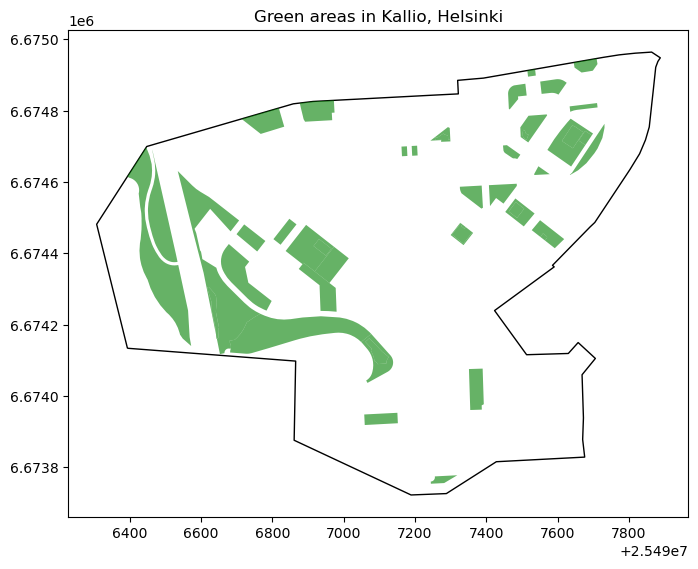

In [27]:
kallio_green_areas = geopandas.read_file(
    build_wfs_url(
        HELSINKI_WFS,
        "avoindata:YLRE_Viheralue_alue",
        srsName="EPSG:3879",
        cql_filter="kaupunginosa = 'Kallio'",
        propertyName="puiston_nimi,luokka,kaupunginosa,viheralueen_pa,geom",
    )
)
print(f"{len(kallio_green_areas)} green areas in Kallio")

ax = kallio.plot(figsize=(8, 8), facecolor="none", edgecolor="black")
kallio_green_areas.plot(ax=ax, color="green", alpha=0.6)
ax.set_title("Green areas in Kallio, Helsinki")

Finally, save the data to a file, so that we do not need to download them
again. As we did in earlier lessons, we write them to a *GeoPackage* with a
layer name:

In [28]:
kallio.to_file(DATA_DIRECTORY / "kallio.gpkg", layer="district")
kallio_green_areas.to_file(DATA_DIRECTORY / "kallio.gpkg", layer="green_areas")

---


## Working with a WMS

A **Web Map Service** does not send us the features, but a *picture* of a map.
We tell the server which layers we want to see, for which area, in which
CRS, and how large the image should be. The server draws the map and sends
the image.

This is useful in two cases: when we only want a *background* for a map (such
as a base map or an aerial photograph, which are rasters and not vector features
anyway), and when the data are too large to download as features.

### Connect and explore

Connecting works just like with a WFS: create a `WebMapService` object. Here,
we use the WMS of the City of Helsinki:

In [29]:
HELSINKI_WMS = "https://kartta.hel.fi/ws/geoserver/avoindata/wms"

wms = WebMapService(HELSINKI_WMS, version="1.3.0")

print(wms.identification.title)
print(wms.provider.name)
print([operation.name for operation in wms.operations])

Helsinki_WMS
Helsingin kaupunki
['GetCapabilities', 'GetMap', 'GetFeatureInfo']


The WMS supports the operations we expected: `GetCapabilities`, `GetMap`, and
`GetFeatureInfo`. Let’s look for aerial photographs (*ortoilmakuva*) and base
maps (*kantakartta*) among the layers:

In [30]:
for name, layer in wms.contents.items():
    if "ortoilmakuva" in name.lower() or "kantakartta" in name.lower():
        print(f"{name:40}{layer.title}")

avoindata:Kantakartta                   Kantakartta
avoindata:Kantakartta_harmaa            Kantakartta_harmaa
avoindata:Kantakartta_varillinen        Kantakartta_varillinen
avoindata:Kantakartta_rajat             Kantakartta_rajat
avoindata:Kantakartta_valkoinen         Kantakartta_valkoinen
avoindata:Kantakartta_pohja             Kantakartta_pohja
avoindata:Kantakartta_paakohteet        Kantakartta_paakohteet
avoindata:Ortoilmakuva                  Ortoilmakuva
avoindata:Ortoilmakuva_2026_5cm         Ortoilmakuva_2026_5cm
avoindata:Ortoilmakuva_2025_5cm         Ortoilmakuva_2025_5cm
avoindata:Ortoilmakuva_2024_5cm         Ortoilmakuva_2024_5cm
avoindata:Ortoilmakuva_2024_30cm        Ortoilmakuva_2024_30cm
avoindata:Ortoilmakuva_2023_5cm         Ortoilmakuva_2023_5cm
avoindata:Ortoilmakuva_2023_HSY_5cm     Ortoilmakuva_2023_HSY_5cm
avoindata:Ortoilmakuva_2022_5cm         Ortoilmakuva_2022_5cm
avoindata:Ortoilmakuva_2021_5cm         Ortoilmakuva_2021_5cm
avoindata:Ortoilmakuva_2021_10c

Let’s look at the most recent *aerial photograph* layer, `avoindata:Ortoilmakuva`,
in more detail. The metadata of a WMS layer are similar to those of a WFS
layer, with two additions: the *styles* that the server can draw the layer
in, and whether the layer is *queryable* (more on that below):

In [31]:
layer = wms.contents["avoindata:Ortoilmakuva"]

print(f"Title:      {layer.title}")
print(f"Extent:     {layer.boundingBoxWGS84}")
print(f"EPSG:3879:  {'EPSG:3879' in [str(crs) for crs in layer.crsOptions]}")
print(f"Styles:     {list(layer.styles)}")
print(f"Queryable:  {bool(layer.queryable)}")

Title:      Ortoilmakuva
Extent:     (24.764732945863038, 60.0080107531311, 25.289558715996222, 60.322459856333225)
EPSG:3879:  True
Styles:     ['default-style-avoindata:06_ortoilmakuvat', 'rasteri']
Queryable:  False


And these are the image formats that the service can produce. Use `image/png`
for maps with sharp lines and for maps that have transparent parts, and
`image/jpeg` for photographs (the files are smaller):

In [32]:
wms.getOperationByName("GetMap").formatOptions[:3]

['image/png', 'application/atom+xml', 'application/json;type=geojson']

---


### Request a map image

A **GetMap** request needs the following parameters:

- `layers`: the layer (or layers) that we want to see,
- `srs`: the CRS of the map (OWSLib calls this parameter `srs`, even if it is
  named `crs` in WMS 1.3.0),
- `bbox`: the area that we want to see, as `(minx, miny, maxx, maxy)` in
  the units of the CRS,
- `size`: the size of the image in *pixels*, as `(width, height)`, and
- `format`: the image format.

Let’s request an aerial photograph of Helsinki’s city centre. We use
`EPSG:3879`, in which coordinates are in metres, and a bounding box of 2.5 km
× 2 km:

In [33]:
bbox = (25496000, 6673000, 25498500, 6675000)

response = wms.getmap(
    layers=["avoindata:Ortoilmakuva"],
    srs="EPSG:3879",
    bbox=bbox,
    size=(750, 600),
    format="image/png",
)

The response is a file-like object. We can read the *bytes* from it, and let
`matplotlib` decode the image into an array of pixel values. To place the image
at the correct location, we pass the bounding box as `extent` to `imshow()`:

(600, 750, 3)


Text(0.5, 1.0, 'Aerial photograph of Helsinki city centre')

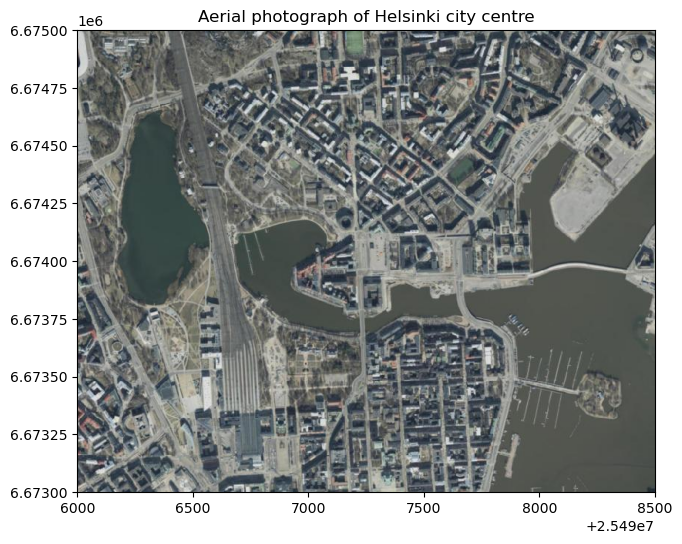

In [34]:
image = plt.imread(io.BytesIO(response.read()), format="png")
print(image.shape)

minx, miny, maxx, maxy = bbox
fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(image, extent=(minx, maxx, miny, maxy))
ax.set_title("Aerial photograph of Helsinki city centre")

Do you notice that the axes show real coordinates? Because we told `imshow()`
where the image is located on the map, we can combine it with vector data in the
same CRS (see below).

The shape of the image array is `(rows, columns, colour bands)`: *600 rows* and
*750 columns* of pixels (the size we asked for), each with its red, green, and
blue values.

<div style="border-left: 5px solid #f5c242; padding: 10px; background-color: #fff3cd; margin: 10px 0;">
<strong>Note: Mind the aspect ratio</strong>
<p>The server draws the map into exactly the size we ask for. If the ratio of
<code>size</code> is different from the ratio of the bounding box, the map is
<em>stretched</em>. Our bounding box is 2 500 m wide and 2 000 m high, which is a ratio of 5 : 4;
and 750 : 600 is also 5 : 4. 🙂</p>
</div>

To avoid mistakes, we write a function that does the calculation for us: we
decide on the width, it computes the matching height, requests the image, and
returns it:

In [35]:
def get_map_image(wms, layers, bbox, crs, width=800, image_format="image/png", **kwargs):
    """Request a map image from a WMS, with the correct aspect ratio."""
    minx, miny, maxx, maxy = bbox
    height = round(width * (maxy - miny) / (maxx - minx))

    response = wms.getmap(
        layers=layers,
        srs=crs,
        bbox=bbox,
        size=(width, height),
        format=image_format,
        **kwargs,
    )
    return plt.imread(io.BytesIO(response.read()), format=image_format.split("/")[-1])

The function passes all other keyword arguments on to `getmap()` (using
`**kwargs`, which works just like `**parameters` above). Let’s use it to compare the *base map*
with the *aerial photograph*, for the same area:

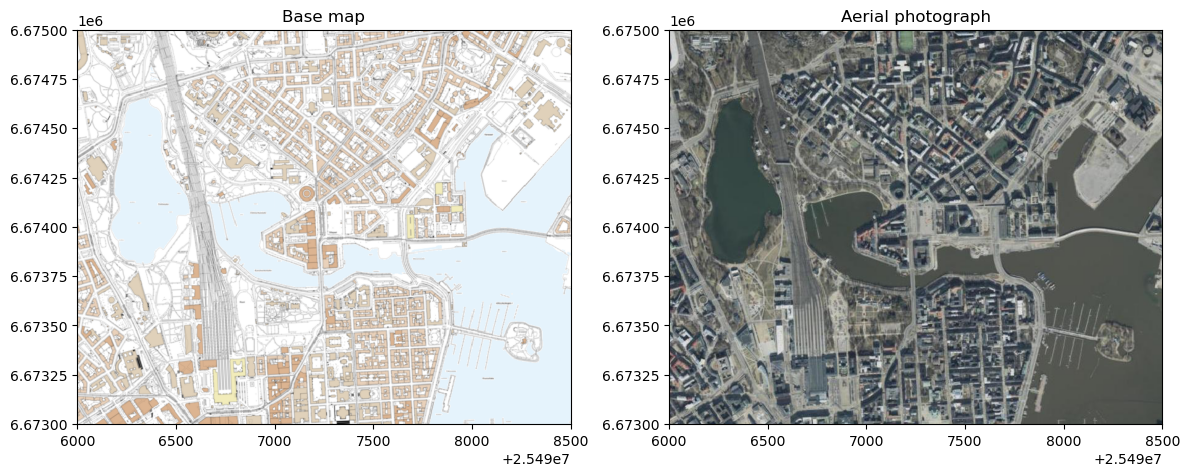

In [36]:
base_map = get_map_image(wms, ["avoindata:Kantakartta"], bbox, "EPSG:3879")
aerial_photograph = get_map_image(
    wms, ["avoindata:Ortoilmakuva"], bbox, "EPSG:3879", image_format="image/jpeg"
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, image, title in zip(
    axes, [base_map, aerial_photograph], ["Base map", "Aerial photograph"]
):
    ax.imshow(image, extent=(minx, maxx, miny, maxy))
    ax.set_title(title)

---


### Image size and level of detail

The `size` that we ask for determines the number of pixels in the image, *not*
the area. The same bounding box in a smaller image is a *coarser* map; in a
larger image, we can see more detail. In the latter case, however, we also
download more data and wait longer.

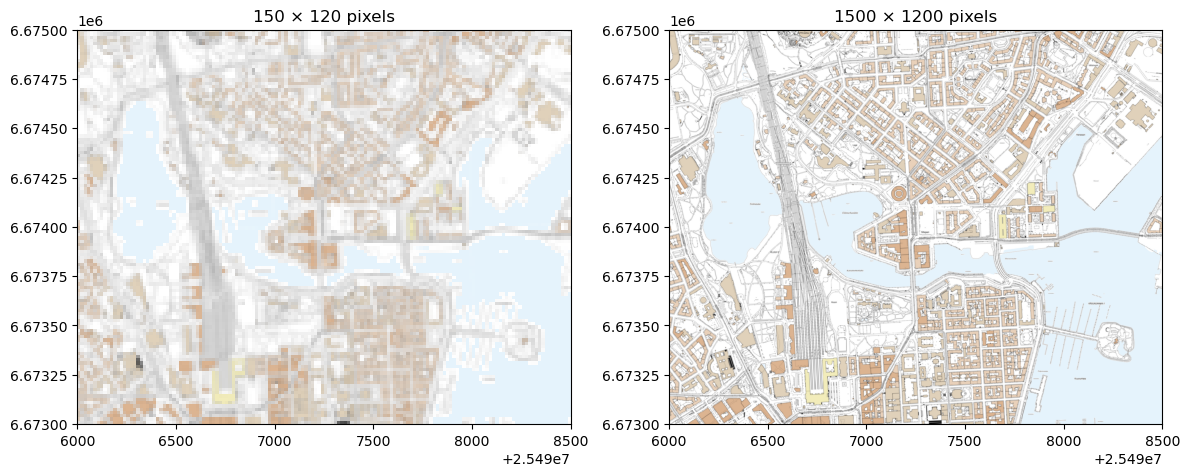

In [37]:
small = get_map_image(wms, ["avoindata:Kantakartta"], bbox, "EPSG:3879", width=150)
large = get_map_image(wms, ["avoindata:Kantakartta"], bbox, "EPSG:3879", width=1500)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, image in zip(axes, [small, large]):
    ax.imshow(image, extent=(minx, maxx, miny, maxy))
    ax.set_title(f"{image.shape[1]} × {image.shape[0]} pixels")

---


### Several layers and transparency

We can ask for several layers in one request: pass a list with all layer names.
The server draws them on top of each other, *the first layer at the bottom*.
If we want to see the layers below, the upper layers need to have transparent
background. Request `transparent=True` for that (and use the `image/png`
format, as `jpeg` cannot be transparent).

The WMS of **HSY** offers, among many other things, aerial photographs and the
city districts (*kaupunginosat*) of the Helsinki region. Let’s draw the
district boundaries on top of an aerial photograph:

Text(0.5, 1.0, 'City districts on top of an aerial photograph')

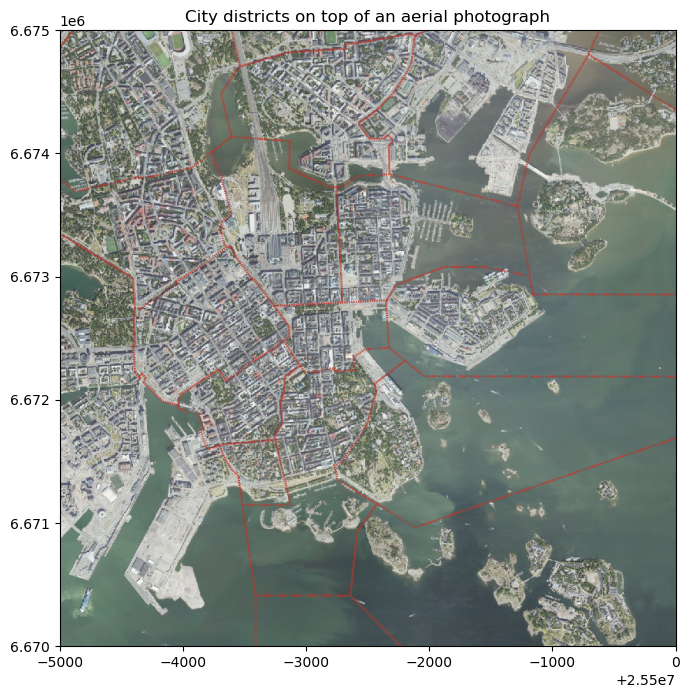

In [38]:
hsy_wms = WebMapService("https://kartta.hsy.fi/geoserver/wms", version="1.3.0")

hsy_layers = [
    "taustakartat_ja_aluejaot:Ortoilmakuva_2023",  # bottom
    "taustakartat_ja_aluejaot:kaupunginosat_2022",  # top
]
hsy_bbox = (25495000, 6670000, 25500000, 6675000)

image = get_map_image(hsy_wms, hsy_layers, hsy_bbox, "EPSG:3879", transparent=True)

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(image, extent=(hsy_bbox[0], hsy_bbox[2], hsy_bbox[1], hsy_bbox[3]))
ax.set_title("City districts on top of an aerial photograph")

---


### Styles and legends

Which layers are drawn is decided by us, but *how* they are drawn, the
**style** (colours, line widths, and so on), is decided by the *server*. A
layer may offer several predefined styles, which we can select with the
`styles` parameter of `getmap()` (one for each layer). If we do not ask for
one, we get the default style.

For the next examples, let’s use the WMS of **Statistics Finland**. It offers
the population of each municipality (`vaestoalue:kunta_vaki2025`) as a ready
made thematic map. Let’s have a look at the layer:

In [39]:
STATISTICS_FINLAND_WMS = "https://geo.stat.fi/geoserver/wms"
POPULATION_LAYER = "vaestoalue:kunta_vaki2025"

stat_wms = WebMapService(STATISTICS_FINLAND_WMS, version="1.3.0")
population_layer = stat_wms.contents[POPULATION_LAYER]

print(f"Title:      {population_layer.title}")
print(f"Styles:     {list(population_layer.styles)}")
print(f"Queryable:  {bool(population_layer.queryable)}")

Title:      Väestö 2025 vuoden 2026 kuntajaolla
Styles:     ['vaestoalue:aluevaki_kunta']
Queryable:  True


The title says: population in 2025, using the municipality division of 2026.
The layer is queryable, and has exactly one style. We therefore do not need to
select anything. Let’s request a map of the whole country. The CRS
`EPSG:3067` is the national standard, and the bounding box below covers
mainland Finland:

Text(0.5, 1.0, 'Population by municipality, 2025 (WMS)')

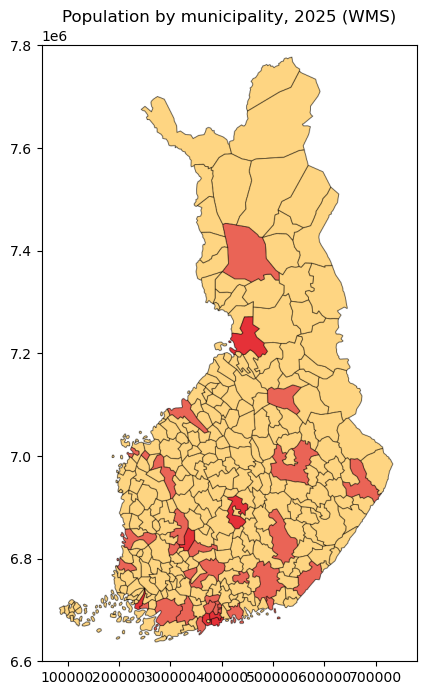

In [40]:
finland_bbox = (50000, 6600000, 780000, 7800000)

finland_map = get_map_image(
    stat_wms, [POPULATION_LAYER], finland_bbox, "EPSG:3067", width=600
)

minx, miny, maxx, maxy = finland_bbox
fig, ax = plt.subplots(figsize=(5, 8))
ax.imshow(finland_map, extent=(minx, maxx, miny, maxy))
ax.set_title("Population by municipality, 2025 (WMS)")

The server has coloured the municipalities in three classes. But what do the
colours mean? A map without a legend is difficult to read. A WMS can also draw
the legend for us (the **GetLegendGraphic** request). The metadata of the
style already contain the URL where the legend image is located:

https://geo.stat.fi/geoserver/ows?service=WMS&version=1.3.0&request=GetLegendGraphic&format=image%2Fpng&width=20&height=20&layer=vaestoalue%3Akunta_vaki2025


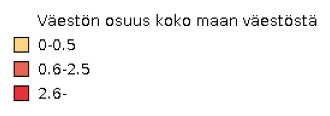

In [41]:
style = list(population_layer.styles.values())[0]
legend_url = style["legend"]
print(legend_url)

legend = plt.imread(io.BytesIO(requests.get(legend_url).content), format="png")

fig, ax = plt.subplots(figsize=(4, 1.5))
ax.imshow(legend)
ax.set_axis_off()

The legend tells us that the map shows each municipality’s *share of the total
population of Finland*, in classes. Not all services provide such a helpful
legend: some only return a generic symbol, others nothing at all. If you use a
WMS for a map in a report, check whether the legend tells you what you need.
And if you cannot get what you need from a WMS: ask for the *features* from the
WFS, and design your own map (see below).

---


### Ask what is there: `GetFeatureInfo`

A picture does not tell us *which* object we see at a given spot, let alone its
attributes. For *queryable* layers, a WMS can answer this, with a
**GetFeatureInfo** request. We send the same parameters as for `GetMap`
(the same bounding box, CRS and image size, so that the server knows the geometry
of the image) and add:

- `query_layers`: the layer(s) that we want to ask about,
- `xy`: the *pixel* that we want to ask about, as `(x, y)`, measured from
  the top left corner of the image, and
- `info_format`: the format of the answer.

We need to tell the server the position as a *pixel* in the image, and not as
a coordinate. A bit of arithmetic converts the coordinate of a place into a
pixel position. Note that the `y` values of pixels count *downwards*, while the
northing of coordinates counts upwards. Let’s ask the service about the
municipality at a location in Helsinki:

In [42]:
x, y = 385800, 6672200  # a location in Helsinki, in EPSG:3067

minx, miny, maxx, maxy = finland_bbox
height, width = finland_map.shape[:2]

pixel_x = round((x - minx) / (maxx - minx) * width)
pixel_y = round((maxy - y) / (maxy - miny) * height)
print(f"The pixel is at x={pixel_x}, y={pixel_y} of an image of {width} × {height}")

response = stat_wms.getfeatureinfo(
    layers=[POPULATION_LAYER],
    query_layers=[POPULATION_LAYER],
    srs="EPSG:3067",
    bbox=finland_bbox,
    size=(width, height),
    info_format="application/json",
    xy=(pixel_x, pixel_y),
)

answer = json.loads(response.read())
answer["features"][0]["properties"]

The pixel is at x=276, y=927 of an image of 600 × 986


{'id': 33,
 'kunta': '091',
 'vuosi': 2026,
 'nimi': 'Helsinki',
 'namn': 'Helsingfors',
 'name': 'Helsinki',
 'til_vuosi': 2025,
 'vaesto': 694392,
 'vaesto_p': 12.3,
 'miehet': 331843,
 'miehet_p': 47.8,
 'naiset': 362549,
 'naiset_p': 52.2,
 'ika_0_14': 96742,
 'ika_0_14p': 13.9,
 'ika_15_64': 474866,
 'ika_15_64p': 68.4,
 'ika_65_': 122784,
 'ika_65_p': 17.7}

The answer contains the attributes of the feature that is drawn at this pixel:
the municipality and its population. So, even if we have only asked for a
picture, we can find out about the data behind it, but for *one location at a
time*.

---


## WMS as a background for vector data

Now we can combine what we learned about the WFS and WMS. A typical use of a
WMS is to put an aerial photograph or a base map *behind* vector data from a
WFS. As both are in the same CRS (`EPSG:3879`), we just draw them into the
same axes: first the image, then the vector features on top.

We use the green areas we have downloaded earlier, and the base map of
Helsinki, for the area of Kallio:

Text(0.5, 1.0, 'Green areas in Kallio')

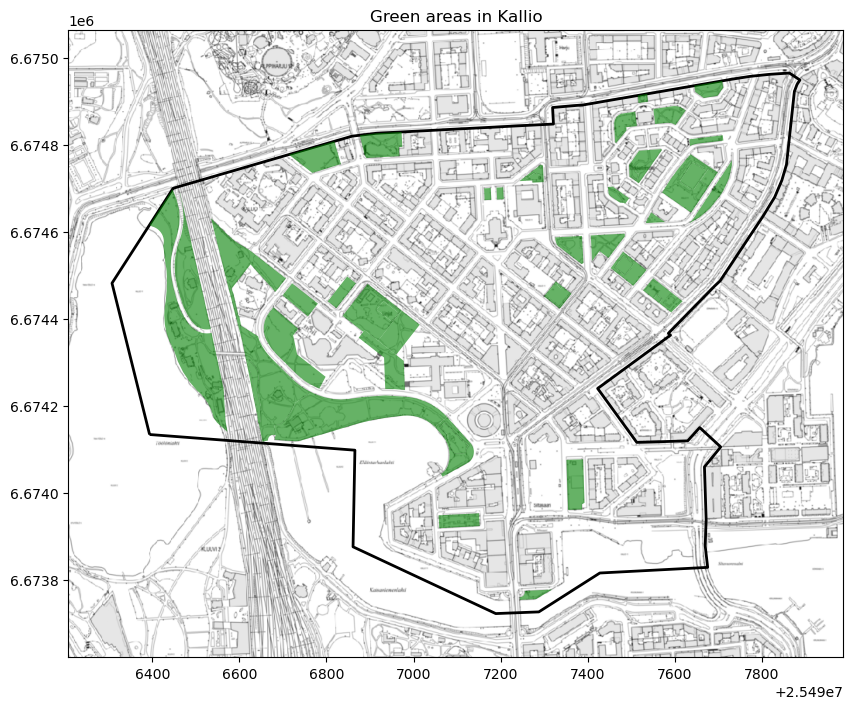

In [43]:
minx, miny, maxx, maxy = kallio.total_bounds
kallio_extent = (minx - 100, miny - 100, maxx + 100, maxy + 100)  # a little margin

background = get_map_image(
    wms, ["avoindata:Kantakartta_harmaa"], kallio_extent, "EPSG:3879", width=1000
)

fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(
    background,
    extent=(kallio_extent[0], kallio_extent[2], kallio_extent[1], kallio_extent[3]),
)
kallio.plot(ax=ax, facecolor="none", edgecolor="black", linewidth=2)
kallio_green_areas.plot(ax=ax, color="green", alpha=0.6)
ax.set_title("Green areas in Kallio")

Let’s stop for a moment to see the difference between the two kinds of data
in this map: the grey base map is only a *picture*, we cannot select anything
in it. But the district and the green areas are *features*, with geometries
and attributes, just like any other `GeoDataFrame`.

---


## WFS or WMS?

Statistics Finland offers the population of the municipalities not only as a
WMS, but also as a WFS, under the same layer name. We already have the
*picture* (`finland_map`, from the WMS). Let’s also download the *features*
from the WFS, and compare them:

In [44]:
population = geopandas.read_file(
    build_wfs_url(STATISTICS_FINLAND_WFS, POPULATION_LAYER, srsName="EPSG:3067")
)
population[["nimi", "vaesto", "vaesto_p", "miehet", "naiset"]].head()

,nimi,vaesto,vaesto_p,miehet,naiset
0,Alajärvi,8982,0.2,4516,4466
1,Alavieska,2384,0.0,1260,1124
2,Alavus,10634,0.2,5452,5182
3,Asikkala,7841,0.1,3894,3947
4,Askola,4677,0.1,2374,2303


The features come with many attributes: the population (`vaesto`), its share
of the population of the whole country (`vaesto_p`), and the numbers of men
and women, and of the age groups. Let’s draw maps of both:

Text(0.5, 1.0, 'WFS: features, styled by us')

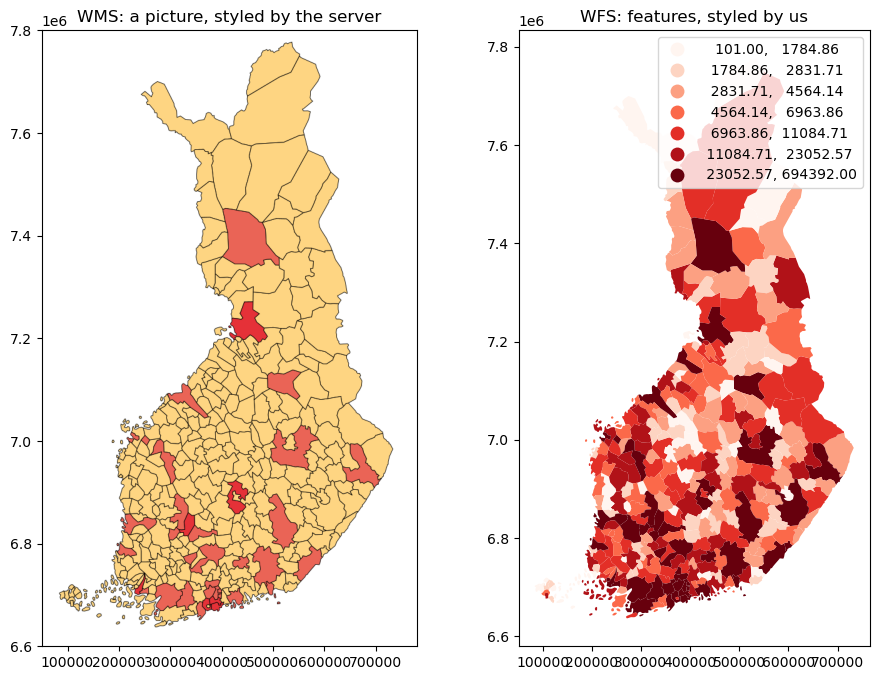

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(11, 8))

axes[0].imshow(finland_map, extent=(finland_bbox[0], finland_bbox[2], finland_bbox[1], finland_bbox[3]))
axes[0].set_title("WMS: a picture, styled by the server")

population.plot(
    ax=axes[1], column="vaesto", cmap="Reds", scheme="quantiles", k=7, legend=True
)
axes[1].set_title("WFS: features, styled by us")

Both maps show the same data. But the WFS gives us the *data*, so we decide
how to draw the map (the variable, the classes, the colours), and we can work
with it like with any other data frame. The picture from the WMS is fixed:
that is how the server has drawn it. These are the rules of thumb to choose
between the two:

| | Use a **WFS** if you… | Use a **WMS** if you… |
|---|---|---|
| Purpose | want to *work with* the data | want to *show* the data |
| Data | need the geometries and attributes | need a background map or an image |
| Size | work with a limited area or a limited number of features | work with a very large data set, or with rasters |
| Styling | want to design the map yourself | are happy with the style of the provider |

---


## When things go wrong

Working with web services means working with *other people’s* computers: they
can be slow, change, or be offline. Here are the most common problems, and what
to do about them.

**The service sends an error message instead of data.** A GetFeature request
for a layer that does not exist returns an *exception report* in XML. Look at
the HTTP status code and the text, they usually tell you what is wrong. Here
is an example, where we mistyped the name of the layer:

In [46]:
response = requests.get(
    build_wfs_url(HSY_WFS, "asuminen_ja_maankaytto:Vaestotietoruudukko_2099")
)

print(response.status_code)
print(response.text[-250:])

400
s/1.1.0/owsAll.xsd">
  <ows:Exception exceptionCode="InvalidParameterValue" locator="typeName">
    <ows:ExceptionText>Feature type asuminen_ja_maankaytto:Vaestotietoruudukko_2099 unknown</ows:ExceptionText>
  </ows:Exception>
</ows:ExceptionReport>



The status code `400` means *bad request*, and the text says: `Feature type
asuminen_ja_maankaytto:Vaestotietoruudukko_2099 unknown`. A good approach
is to always copy the layer names from `wfs.contents` (or `wms.contents`), instead
of typing them. Errors from a WMS that are raised by OWSLib are called
`ServiceException`; their message tells you what went wrong, too.

Here is a list of other typical problems:

| Problem | Likely reason | What to do |
|---|---|---|
| Features end up in the wrong place, or `crs` is `None` | The response has no CRS information, or you used a different `srsName` than you think | Check `gdf.crs`; ask for `srsName` explicitly; as a last resort set the CRS manually with `gdf.crs = "EPSG:XXXX"` (only if you *know* it) |
| Fewer features than expected | The server limits the number of features per response | Compare with `resultType=hits`; download in pages with `startIndex` |
| All features arrive although you filtered | The service does not understand `cql_filter` | Check the number of rows; filter in pandas instead |
| Empty result for a `bbox` | The coordinates are in the wrong order, or in a different CRS than the one named in `bbox` | Use `minx, miny, maxx, maxy`, and *always* append the CRS |
| The WMS image is stretched | `size` and `bbox` have different aspect ratios | Compute the height from the width (our function does this) |
| The WMS image is empty (white or transparent) | The area is outside of the layer’s extent, or the layer is not visible at this scale | Check `layer.boundingBoxWGS84`; request a smaller area |
| `TimeoutError`, `ConnectionError`, or status `5xx` | The service is slow or temporarily down | Try again later; request less data |
| `ModuleNotFoundError: owslib` | The package is not installed | `pip install owslib` or `conda install -c conda-forge owslib` |

<div style="border-left: 5px solid #f5c242; padding: 10px; background-color: #fff3cd; margin: 10px 0;">

**Note: Axis order of geographic coordinates**

For *projected* coordinate systems such as `EPSG:3067` or `EPSG:3879`, the
order is always *x* (easting), then *y* (northing). But for geographic
coordinates (e.g., `EPSG:4326`), different services and versions of the standards
disagree on whether the *longitude* or the *latitude* comes first. This is a
very common source of errors. The easiest way to avoid it: request your data
in a projected CRS, like we did here, and re-project it
afterwards, if necessary.

</div>

<div style="border: 1px solid #cce5ff; background-color: #e9f7fd; padding: 15px; border-radius: 5px;">

**Terms of use, licences, and API keys**

Open data are not necessarily free of conditions. Before you use data from a
web service in a publication or a project, check its *licence* (the metadata
of the layer often have a hint, and the service provider’s web page should
tell you for sure). Many Finnish public authorities use the
[Creative Commons Attribution 4.0 (CC BY 4.0)](https://creativecommons.org/licenses/by/4.0/)
licence, which means that you need to mention the source. Some services (for
example, those of the National Land Survey) also require an *API key*, which
you pass as an additional parameter of your request, or as part of the URL.
Never publish your API key, for instance in a public GitHub repository!

</div>

---


## Summary

We have seen how to use web services to load data in Python:

- **WFS** serves *features* (geometries and attributes). We explore a service
  with *OWSLib* (`WebFeatureService`, `contents`, `get_schema()`), and
  download data with a `GetFeature` request, using `geopandas.read_file()`.
  Parameters like `srsName`, `bbox`, `cql_filter`, `propertyName`, `count`,
  and `startIndex` select the data on the server.
- **WMS** serves *pictures* of maps. With `WebMapService`, we explore the
  service and use `getmap()` to request an image of a bounding box in a given
  CRS and image size. `getfeatureinfo()` tells us about the objects in the map,
  and the style’s legend URL gives us the legend.
- Both can be combined: draw a WMS image as a background, and the WFS
  features on top of it.

### Try it yourself

1. Explore the layers of Statistics Finland’s WFS (the workspace
   `tilastointialueet` is only one of many!). Find a layer with a theme you are
   interested in, and describe it with its metadata and schema.
2. How many **regions** (*maakunta*) and how many **municipalities** does
   Finland have in 2026? Find out *without* downloading the features (hint:
   `resultType=hits`).
3. Download Helsinki’s city districts and request an aerial photograph of the
   district where you live. Draw the district’s border on top of it.
4. Find the layers of **HSY** that show the *land cover* (*maanpeite*), and
   draw a map of one of them with the WMS. Can you also get it with the WFS?
5. Write a function that downloads *all* features of a WFS layer in pages,
   given the URL of the service and the name of a layer.

### Further reading

- [OWSLib documentation](https://owslib.readthedocs.io/en/latest/usage.html):
  more about WFS and WMS (and other services) in Python
- [GeoServer’s CQL tutorial](https://docs.geoserver.org/latest/en/user/tutorials/cql/cql_tutorial.html)
- [Geopandas user guide](https://geopandas.org/en/stable/docs/user_guide/io.html):
  reading data from files and URLs
- [Paikkatietoikkuna](https://www.paikkatietoikkuna.fi/), Finland’s geospatial
  platform, to find more data sets and services